### Generate an NFW Halo Profile

Generate a txt file containing a static NFW host halo information. Used for N-body simulation.

**1. Density Profile** 
The mass density $\rho(r)$ follows the standard NFW analytical form:

$$\rho(r) = \frac{\rho_s}{\frac{r}{r_s} \left( 1 + \frac{r}{r_s} \right)^2}$$

Where:
* $\rho_s$ is the characteristic density ($650546 \, M_\odot/\text{kpc}^3$).
* $r_s$ is the scale radius ($149.909$ kpc).

**2. Enclosed Mass**
The total mass $M(<r)$ contained within a sphere of radius $r$ is calculated by integrating the density profile:

$$M(<r) = 4\pi \rho_s r_s^3 \left[ \ln\left(1 + \frac{r}{r_s}\right) - \frac{r/r_s}{1 + r/r_s} \right]$$

**3. Velocity Dispersion**
For this profile, the radial velocity dispersion $\sigma_v(r)$ is approximated using the circular velocity at a given radius, assuming a state of virial equilibrium:

$$\sigma_v(r) \approx \sqrt{\frac{G M(<r)}{r}}$$

Where $G$ is the gravitational constant.

---

### Data Columns
1. **r [kpc]**: Radial distance from the halo center.
2. **rho(r) [Msun/kpc3]**: Local mass density.
3. **M(<r) [Msun]**: Cumulative enclosed mass.
4. **sigma_v(r) [km/s]**: Radial velocity dispersion.

In [19]:
import numpy as np

# Halo parameters
rs = 149.909         # kpc
rhos = 650546        # Msun/kpc^3
rvir = 974.407       # kpc
G = 6.67e-11         # Gravitational constant in m^3 kg^-1 s^-2

#### add a conversion factor for G to match units of Msun, kpc, and km/s ####
mtokpc = 3.24*1e-20  # meters to kiloparsecs
kgtoMsun = 1/(1.989e30)  # kilograms to solar masses
stoGyr = 1/(365*24*3600*1e9)  # seconds to gigayears
G = G * (kgtoMsun**-1) * (mtokpc**3) * (stoGyr**-2)  # G in units of kpc^3
print(G)

# Define the radial range (from very close to center out to Virial Radius)
#### TO DO: r = np.linspace() 
r = np.linspace(0.1, rvir, 500) 

# Density: rho(r)
#### TO DO: define rho(r)
rho_r = rhos/((r/rs) * (1 + r/rs)**2)

# Enclosed Mass: M(<r)
#### TO DO: define mass_enclosed(r)
M_r = 4 * np.pi * rhos * rs**3 * (np.log(1 + r/rs) - (r/rs)/(1 + r/rs))

# Radial Velocity Dispersion: sigma_v(r)
# Note: This is the circular velocity approximation sqrt(GM/r)
#### TO DO: define sigma_v(r)
v_r = np.sqrt(G * M_r / r)

# Stack the results into a single array for saving
#### TO DO: data = np.column_stack()

# Save to a text file
#### To DO: np.savetxt()

print("Success! txt file has been generated.")

4.487545464206531e-06
Success! txt file has been generated.


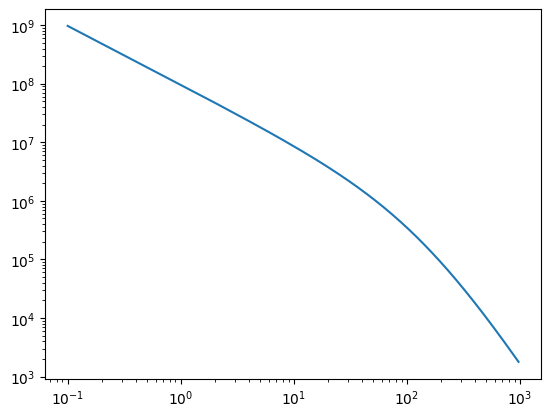

In [12]:
import matplotlib.pyplot as plt

plt.loglog(r, rho_r)

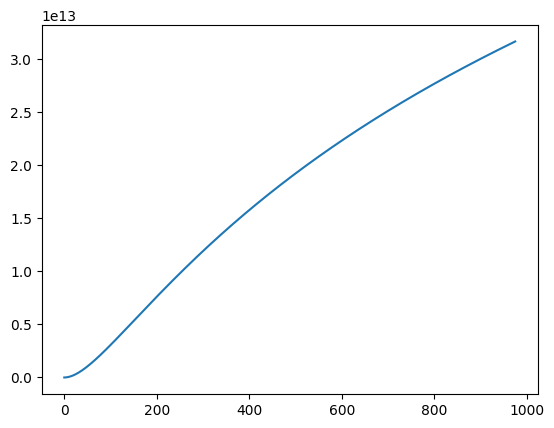

In [17]:
plt.plot(r, M_r)

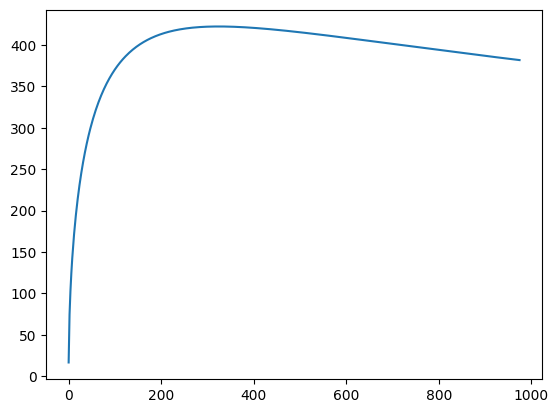

In [20]:
plt.plot(r, v_r)